In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" / "singlish_cleaned.csv"
)

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7831, 2)


,Comments,Sentiment
0,me price dala thiyana widiha hoidai wadi wisth...,Pos
1,ekata nam matath aduna chuti nangiyo oya ayyat...,Neu
2,hoda wada sathanak,Pos
3,ela ela aiya api oyata hamadamath adare,Pos
4,hikvision hodai cctv walata owa nam melo sasar...,Neg


In [2]:

X = df["Comments"].fillna("").astype(str)
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

best_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    ("classifier", LinearSVC(random_state=42))
])

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Linear SVM training and prediction completed.")
print("Test samples:", len(y_test))


Linear SVM training and prediction completed.
Test samples: 1567


In [3]:

labels = ["Pos", "Neg", "Neu"]

report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=["Positive", "Negative", "Neutral"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))


,precision,recall,f1-score,support
Positive,0.8029,0.8499,0.8257,853.0000
Negative,0.6853,0.6280,0.6554,371.0000
Neutral,0.4938,0.4665,0.4798,343.0000
accuracy,0.7135,0.7135,0.7135,0.7135
macro avg,0.6607,0.6481,0.6536,1567.0000
weighted avg,0.7074,0.7135,0.7097,1567.0000


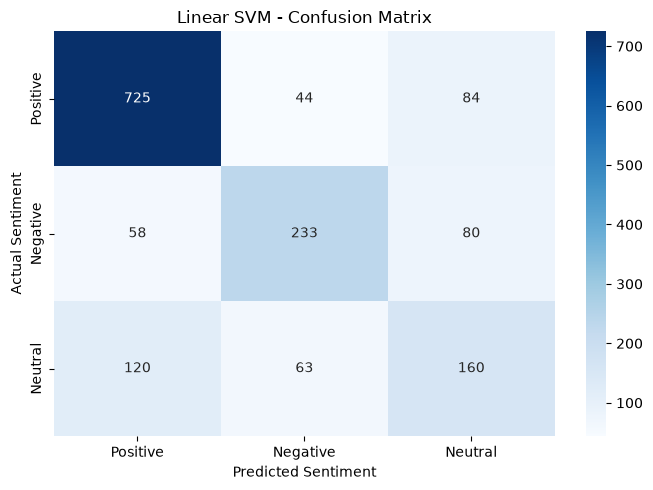

In [4]:

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Positive", "Negative", "Neutral"],
    yticklabels=["Positive", "Negative", "Neutral"]
)

plt.title("Linear SVM - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "linear_svm_confusion_matrix.png",
    dpi=300
)

plt.show()


In [5]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = pd.DataFrame([{
    "Model": "Linear SVM",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Macro Precision": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
}])

display(evaluation_results.round(4))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Linear SVM,0.7135,0.6607,0.6481,0.6536


In [6]:

report_df.to_csv(
    TABLES_DIR / "linear_svm_classification_report.csv"
)

evaluation_results.to_csv(
    TABLES_DIR / "linear_svm_evaluation_metrics.csv",
    index=False
)

print("Evaluation tables saved successfully!")
print("Figures saved in:", FIGURES_DIR)
print("Tables saved in:", TABLES_DIR)


Evaluation tables saved successfully!
Figures saved in: c:\Users\chami\OneDrive\Desktop\Singlish_Sentiment_Analysis\reports\figures
Tables saved in: c:\Users\chami\OneDrive\Desktop\Singlish_Sentiment_Analysis\reports\tables


In [7]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

evaluation_summary = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    }
])

display(evaluation_summary.round(4))

evaluation_summary.to_csv(
    TABLES_DIR / "linear_svm_evaluation_metrics.csv",
    index=False
)

print("Evaluation metrics saved successfully!")


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Linear SVM,0.7135,0.6607,0.6481,0.6536


Evaluation metrics saved successfully!


In [8]:

import joblib

MODEL_PATH = PROJECT_ROOT / "models" / "best_sentiment_model.joblib"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, MODEL_PATH)

print("Model saved successfully!")
print("Model location:", MODEL_PATH)


Model saved successfully!
Model location: c:\Users\chami\OneDrive\Desktop\Singlish_Sentiment_Analysis\models\best_sentiment_model.joblib
